# 第04回：Attentionの計算とESM-2の穴埋め予測
**20分／採点・記述提出・回答送信なし**

講義のAttentionの数値例を動かしてから、実際のESM-2でユビキチン（PDB 1UBQ、76残基）の配列を読みます。

1. **Attentionの模型**：Queryの位置と因果マスクを変え、重みと出力を見る。
2. **実際のESM-2**：隠す位置を12・23・44・66番から選び、候補を見る。
3. **周囲の文脈**：対象残基と組成を保ち、周囲の順序だけを変えて比較する。

[授業のColabリンク](https://colab.research.google.com/github/matsunagalab/lecture_bioinfo/blob/main/04_%E7%94%9F%E5%91%BD%E7%A7%91%E5%AD%A6%E3%81%AE%E8%A8%80%E8%AA%9E%E3%83%A2%E3%83%87%E3%83%AB/%E7%AC%AC04%E5%9B%9E_ESM2%E3%81%A7%E9%85%8D%E5%88%97%E3%82%92%E8%AA%AD%E3%82%80.ipynb)から開き、Googleアカウントでログインして、上から実行します。ダウンロード・アップロードは不要です。編集内容を残す場合は「ドライブにコピーを保存」を使ってください。CPUで動き、APIキーは不要です。モデル準備が3分で終わらなければ中断し、`第04回_計算済み出力.html` を開いてください。模型はその場で再計算し、ESM-2は保存済みの同じ8条件を表示します。

## 1　3位置のAttentionを計算する
学習済みESM-2の内部値ではなく、**講義と同じ説明用の行列**です。

\(H=I_3\) として、\(Q=HW_Q\)、\(K=HW_K\)、\(V=HW_V\) を作ります。`query_position=1`、`causal=False` では、重みは約 **(0.4011, 0.1978, 0.4011)**、出力は約 **(1.2033, 0.7967)**。

- Queryを1→2へ変えると、内積が変わる。
- Queryを2のまま `causal=True` にすると、位置3の重みが0になる。
- Valueは固定したまま、重みの違いが出力へどう反映されるかを見る。

因果マスクは未来の位置を参照させない操作。ESM-2の[MASK]は予測対象の文字を隠す操作で、両者は異なります。

Q = [[1. 0.]
 [0. 1.]
 [1. 1.]] 
K = [[1. 0.]
 [0. 1.]
 [1. 1.]] 
V = [[1. 0.]
 [0. 2.]
 [2. 1.]]
Query position: 1 | causal: False
Scores: [0.7071 0.     0.7071] 
Attention weights: [0.4011 0.1978 0.4011] 
Output: [1.2033 0.7967]


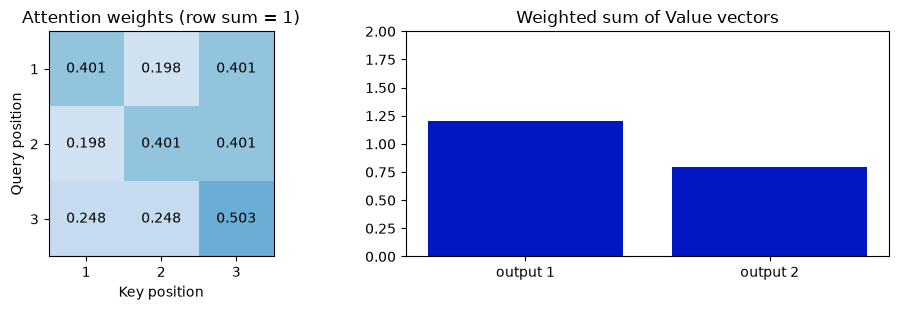

In [1]:
# @title Queryと参照範囲を選ぶ
query_position = 1 # @param [1,2,3] {type:"raw"}
causal = False # @param {type:"boolean"}
import numpy as np
import matplotlib.pyplot as plt
H = np.eye(3)
WQ = WK = np.array([[1.,0.],[0.,1.],[1.,1.]])
WV = np.array([[1.,0.],[0.,2.],[2.,1.]])
Q, K, V = H @ WQ, H @ WK, H @ WV
scores = Q @ K.T / np.sqrt(K.shape[1])
if causal:
    scores[np.triu_indices(3, k=1)] = -np.inf
weights = np.exp(scores - scores.max(axis=1, keepdims=True))
weights /= weights.sum(axis=1, keepdims=True)
output = weights @ V
np.set_printoptions(precision=4, suppress=True)
i = query_position - 1
print("Q =",Q,"\nK =",K,"\nV =",V)
print("Query position:",query_position,"| causal:",causal)
print("Scores:",scores[i],"\nAttention weights:",weights[i],"\nOutput:",output[i])
fig, ax = plt.subplots(1,2,figsize=(10,3.2))
im=ax[0].imshow(weights,vmin=0,vmax=1,cmap="Blues")
for r in range(3):
    for c in range(3): ax[0].text(c,r,f"{weights[r,c]:.3f}",ha="center",va="center",color="white" if weights[r,c]>.6 else "black")
ax[0].set(xticks=range(3),yticks=range(3),xticklabels=[1,2,3],yticklabels=[1,2,3],xlabel="Key position",ylabel="Query position",title="Attention weights (row sum = 1)")
ax[1].bar(["output 1","output 2"],output[i],color="#0017c1");ax[1].set_ylim(0,2);ax[1].set_title("Weighted sum of Value vectors")
plt.tight_layout();plt.show()
assert np.allclose(weights.sum(1),1)


## 2　実際のESM-2を準備する
ここからは**実際に学習されたモデル**を使います。模型のQ・K・Vは渡しません。

`esm2_t6_8M_UR50D` は6層・表現320次元の小型モデルです。下のセルは必要なライブラリを準備し、モデルを読み込みます。準備できなかった場合も、次のセルは保存済み出力で動きます。

In [2]:
import importlib.util, subprocess, sys, time, random
model = alphabet = converter = None
try:
    if importlib.util.find_spec("esm") is None:
        subprocess.run([sys.executable,"-m","pip","-q","install","fair-esm==2.0.0"],check=True,timeout=120)
    import torch, esm
    torch.set_num_threads(2)
    model, alphabet = esm.pretrained.esm2_t6_8M_UR50D()
    model.eval()
    converter = alphabet.get_batch_converter()
    print("実モデルの準備完了：ESM-2 8M / CPU")
except Exception as exc:
    model = None
    print("実モデルの準備ができなかったため、計算済み出力を使います。",type(exc).__name__)


実モデルの準備完了：ESM-2 8M / CPU


## 3　隠す位置を切り替える
位置は**1始まりの残基番号**です。先頭に特殊トークンが1個入るため、この実装のトークン添字と残基番号は一致します。

- まず23番、次に12番・44番・66番を選び、条件セルとその次のセルを再実行する。
- 同じ位置で候補がどれほど集中するか、位置を変えると何が変わるかを見る。
- I（Ile）・L（Leu）・V（Val）は非極性、K（Lys）は通常正に荷電、T（Thr）は極性の側鎖を持つ。

上位5個は**全語彙でsoftmaxを計算した確率**です。5個だけで再正規化していません。元の文字が常に1位になるとは限りません。

In [3]:
# @title ESM-2の予測条件
position = 23 # @param [12,23,44,66] {type:"raw"}
context = "native" # @param ["native","shuffled_context"]
use_precomputed = False # @param {type:"boolean"}


今回実行した予測（ESM-2 8M / CPU）
入力： MQIFVKTLTGKTITLEVEPSDT[MASK]ENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG
位置： 23 ／隠した元の文字： I
L: 32.29%
V: 23.88%
I: 23.71%
F: 7.89%
W: 2.72%


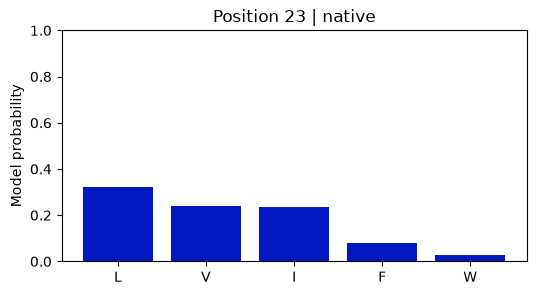

In [4]:
CACHE = {'model': 'esm2_t6_8M_UR50D', 'fair_esm': '2.0.0', 'torch': '2.14.1', 'sequence': 'MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG', 'device': 'cpu', 'threads': 4, 'cases': [{'position': 12, 'context': 'native', 'original': 'T', 'input_sequence': 'MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG', 'top5': [{'aa': 'E', 'prob': 0.21892209351062775}, {'aa': 'T', 'prob': 0.1311466544866562}, {'aa': 'D', 'prob': 0.09625725448131561}, {'aa': 'K', 'prob': 0.09461205452680588}, {'aa': 'S', 'prob': 0.08928221464157104}], 'seconds': 0.010643959045410156}, {'position': 12, 'context': 'shuffled_context', 'original': 'T', 'input_sequence': 'SFELQNMEIVITYGQGKLNGQILEPDKLTQAIIGGIRQSTDIRLKQTLDEREHPRFKPEVSALKVKTLKTVGTDDL', 'top5': [{'aa': 'E', 'prob': 0.08507221937179565}, {'aa': 'D', 'prob': 0.0823030024766922}, {'aa': 'S', 'prob': 0.07692793756723404}, {'aa': 'G', 'prob': 0.0756354108452797}, {'aa': 'A', 'prob': 0.0690060406923294}], 'seconds': 0.0069828033447265625}, {'position': 23, 'context': 'native', 'original': 'I', 'input_sequence': 'MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG', 'top5': [{'aa': 'L', 'prob': 0.32290321588516235}, {'aa': 'V', 'prob': 0.23876366019248962}, {'aa': 'I', 'prob': 0.23713551461696625}, {'aa': 'F', 'prob': 0.078935906291008}, {'aa': 'W', 'prob': 0.027193771675229073}], 'seconds': 0.006387948989868164}, {'position': 23, 'context': 'shuffled_context', 'original': 'I', 'input_sequence': 'SFELQNMVTVIYGQGKTNGQILIEEDKLDQAITGGIRQPTDIRLKQTLDERLHPRFKPEESALKVKTLKIVGTDSL', 'top5': [{'aa': 'L', 'prob': 0.10170266032218933}, {'aa': 'S', 'prob': 0.0834222361445427}, {'aa': 'I', 'prob': 0.08260525017976761}, {'aa': 'T', 'prob': 0.0759192481637001}, {'aa': 'A', 'prob': 0.07555261999368668}], 'seconds': 0.004967927932739258}, {'position': 44, 'context': 'native', 'original': 'I', 'input_sequence': 'MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG', 'top5': [{'aa': 'L', 'prob': 0.21722222864627838}, {'aa': 'I', 'prob': 0.21533198654651642}, {'aa': 'V', 'prob': 0.2044026404619217}, {'aa': 'F', 'prob': 0.11902078986167908}, {'aa': 'Y', 'prob': 0.04333817586302757}], 'seconds': 0.006058931350708008}, {'position': 44, 'context': 'shuffled_context', 'original': 'I', 'input_sequence': 'SFKLDEMVTNIYGQEKTNGQKLIEQDLDIALTGGGRQPTDIRLIVQTLPEQLHPRFKIEESKLKVATLKIVGTDSR', 'top5': [{'aa': 'L', 'prob': 0.23462046682834625}, {'aa': 'A', 'prob': 0.13104519248008728}, {'aa': 'I', 'prob': 0.11886722594499588}, {'aa': 'F', 'prob': 0.10360973328351974}, {'aa': 'V', 'prob': 0.08632867783308029}], 'seconds': 0.005690813064575195}, {'position': 66, 'context': 'native', 'original': 'T', 'input_sequence': 'MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG', 'top5': [{'aa': 'V', 'prob': 0.19622531533241272}, {'aa': 'E', 'prob': 0.14044418931007385}, {'aa': 'I', 'prob': 0.1262766420841217}, {'aa': 'T', 'prob': 0.11564450711011887}, {'aa': 'K', 'prob': 0.09203518182039261}], 'seconds': 0.006050825119018555}, {'position': 66, 'context': 'shuffled_context', 'original': 'T', 'input_sequence': 'LIKLDEMVTNNDGQEKTYAQKQIEQDLDIFLTGDGRIPTSIRLVKRTPLQLHPGFQIKEEKLKVATSLGIVGTESR', 'top5': [{'aa': 'K', 'prob': 0.13401585817337036}, {'aa': 'E', 'prob': 0.12382804602384567}, {'aa': 'R', 'prob': 0.08806239068508148}, {'aa': 'L', 'prob': 0.08006556332111359}, {'aa': 'Q', 'prob': 0.06521821022033691}], 'seconds': 0.005728006362915039}]}
SEQUENCE = CACHE["sequence"]
def make_sequence(position, context):
    if context == "native": return SEQUENCE
    others = [a for i,a in enumerate(SEQUENCE,1) if i != position]
    random.Random(7).shuffle(others)
    it=iter(others)
    return "".join(a if i==position else next(it) for i,a in enumerate(SEQUENCE,1))
def predict(position, context, use_precomputed=False):
    assert position in [12,23,44,66]
    assert context in ["native","shuffled_context"]
    sequence=make_sequence(position,context)
    if use_precomputed or model is None:
        return next(r for r in CACHE["cases"] if r["position"]==position and r["context"]==context), "保存済みの実計算（ESM-2 8M / CPU）"
    _,_,tokens=converter([("ubiquitin",sequence)])
    tokens[0,position]=alphabet.mask_idx
    with torch.inference_mode():
        # logitsは語彙のスコア。Attentionの重みとは異なります。
        probabilities=model(tokens)["logits"][0,position].softmax(-1)
    values,indices=probabilities.topk(5)
    return dict(position=position,context=context,original=sequence[position-1],input_sequence=sequence,
      top5=[dict(aa=alphabet.get_tok(i),prob=float(v)) for v,i in zip(values,indices)]), "今回実行した予測（ESM-2 8M / CPU）"
row,source=predict(position,context,use_precomputed)
print(source)
s=row["input_sequence"]
print("入力：",s[:position-1]+"[MASK]"+s[position:])
print("位置：",position,"／隠した元の文字：",row["original"])
for a in row["top5"]: print(f'{a["aa"]}: {a["prob"]:.2%}')
plt.figure(figsize=(6,3));plt.bar([a["aa"] for a in row["top5"]],[a["prob"] for a in row["top5"]],color="#0017c1")
plt.ylim(0,1);plt.ylabel("Model probability");plt.title(f"Position {position} | {context}");plt.show()


## 4　同じ位置で、周囲の順序だけを変える
`native` と `shuffled_context` を並べて比較します。後者は対象位置以外を固定乱数で並べ替えた配列で、天然タンパク質や実験済み変異体ではありません。

- **固定するもの**：配列長、アミノ酸組成、対象位置、隠した元の文字、モデル。
- **変えるもの**：周囲のアミノ酸の順序。
- 両方の条件の1位と確率の集中を見比べる。元の並びが常に鋭い分布になるとは限らない。

予測の変化は、モデルが順序を含む文脈へ依存することを示します。実験的な安定性や機能は測っていません。

今回実行した予測（ESM-2 8M / CPU） | native | 隠した文字 I
今回実行した予測（ESM-2 8M / CPU） | shuffled_context | 隠した文字 I


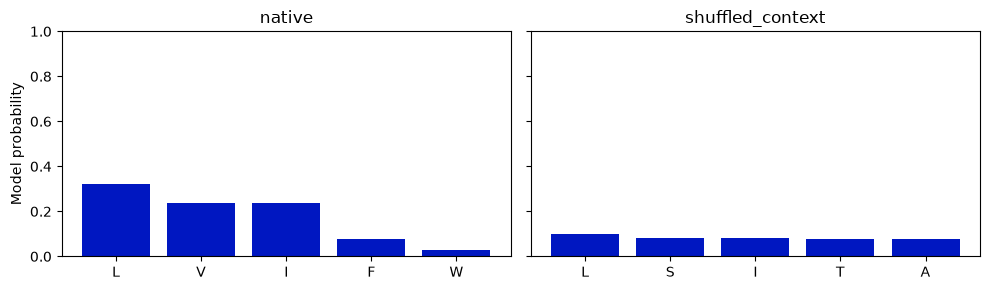

In [5]:
rows=[predict(position,c,use_precomputed) for c in ["native","shuffled_context"]]
assert rows[0][0]["original"]==rows[1][0]["original"]
assert sorted(rows[0][0]["input_sequence"])==sorted(rows[1][0]["input_sequence"])
fig,axes=plt.subplots(1,2,figsize=(10,3),sharey=True)
for ax,(r,label) in zip(axes,rows):
    print(label,"|",r["context"],"| 隠した文字",r["original"])
    ax.bar([a["aa"] for a in r["top5"]],[a["prob"] for a in r["top5"]],color="#0017c1")
    ax.set_title(r["context"]);ax.set_ylim(0,1)
axes[0].set_ylabel("Model probability");plt.tight_layout();plt.show()


## 結果を読むときの注意
- 模型では、QとKから参照の重みを決め、Valueを混ぜた。
- 実際のESM-2は学習済みの複数層を使い、最後の出力層からアミノ酸の確率を返す。
- Attentionの重みと、アミノ酸の予測確率と、接触確率は異なる量。
- 高い予測確率だけでは機能や安定性を確定できない。配列が学習に含まれたかも、この演習では確認していない。
- 一つのタンパク質・一つの小型モデルでは、スケーリング則や未知配列への汎化性能は評価できない。

[ESM公式実装](https://github.com/facebookresearch/esm)（fair-esm 2.0.0）／[Lin et al., Science (2023)](https://doi.org/10.1126/science.ade2574)／[PDB 1UBQ](https://www.rcsb.org/structure/1UBQ)

ローカルCPUでの実行確認とGoogle Colab上の実行確認は別です。Colabで準備できないときは、同梱HTMLで同じ観察ができます。